# 00c · Floor profiles: what only each floor shows

Each group member explored one floor from the raw CSVs, with their own cleaning. This notebook keeps the findings that
are **distinctive to that floor** and re-derives every one from the shared cleaned data (`sbanalytics.data`), so the
numbers agree with 00a, 00b and 01–06. If a finding does not survive on the cleaned data, the floor's section says so
in one line rather than dropping it silently.

Each floor follows the same template: **what's distinctive** (3–5 points) → **KPI row** → 1–2 charts → **checked
against the cleaned data**. Floor N always has the same colour (`sbanalytics.viz`).

| Floor | Owner | In one line |
|---|---|---|
| [F1](#F1) | Leyna | Not an office floor: evening peak, AC never off, clock uncertain |
| [F2](#F2) | Shree | 14 AC units in z2, several running all night; an uncooled zone acts as a control |
| [F3](#F3) | Mik | Full AC programmes on a handful of weekends; plug baseload creeps up |
| [F4](#F4) | Kenneth | All-hours averages hide the overcooling; a reconnect burst on 2018-11-21 |
| [F5](#F5) | Terence | The metering traps: z1 on AC4, a supply-air sensor, a z2↔z4 meter transfer |
| [F6](#F6) | Williams | Truncated file; the four-unit zone is z4; year on year flat |
| [F7](#F7) | Sana | Dead z1_AC1, the most weekend AC, the most overcooling |

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="obj.round has no effect")
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # viz falls back from Segoe UI quietly

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# `pip install -e .` from the repo root makes `sbanalytics` importable; this fallback works without it.
try:
    import sbanalytics
except ImportError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sbanalytics").is_dir()) / "src"))

from sbanalytics import data as D, registry as R, viz
viz.setup()
pd.set_option("display.precision", 2)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 120)
from sbanalytics import baseline as B, kpis as K, anomaly as AN, config as C

In [2]:
h = D.load_hourly(None)
fh = B.floor_hourly(h)
fd = B.floor_daily(fh)
hp = D.load_hourly_points(None)
hp["ts"] = pd.to_datetime(hp.ts)
health = D.load_health(None)
health = health[health.role != R.ROLE_DEAD]
POWER, SENSORS = ["ac", "light", "plug"], ["temp", "rh", "lux"]
LO, HI = R.conv("comfort_lo"), R.conv("comfort_hi")

def point(f, col):
    """Hourly kWh of one raw meter column (cleaned)."""
    return hp[(hp.floor == f) & (hp.column == col)].set_index("ts").value.sort_index()

def pct(d):
    return d.received.sum() / d.expected.sum() * 100

# --- the KPI row every floor section shows --------------------------------------------------
kpi = K.floor_kpis(fh, fd)
comfort = K.zone_comfort(h)
w = comfort.assign(wt=comfort.ac_kwh_in_window)
kpi["overcooled"] = (w.share_below_lo * w.wt).groupby(w.floor).sum() / w.wt.groupby(w.floor).sum()
ah = AN.after_hours_ac(fh)
ac_runs = ah[ah.day_type.isin(["weekend", "holiday", "closure"]) & (ah.hours >= 4)]   # full AC programmes on days off

KPI = pd.DataFrame({
    "kWh/day": kpi.kwh_per_day.map("{:,.0f}".format),
    "AC share": kpi.ac_share.map("{:.0%}".format),
    "after-hours AC share": kpi.after_hours_ac_share.map("{:.0%}".format),
    "occupied cooled hours < 23 °C": kpi.overcooled.map("{:.0%}".format, na_action="ignore"),
    "days off with a ≥ 4 h AC run": ac_runs.groupby("floor").size().reindex(C.FLOORS, fill_value=0).astype(str),
    "power data received": health[health.channel.isin(POWER)].groupby("floor").apply(pct, include_groups=False).map("{:.1f}%".format),
    "sensor data received (outside blackout)": health[health.channel.isin(SENSORS) & ~health.in_blackout]
        .groupby("floor").apply(pct, include_groups=False).map("{:.1f}%".format),
}).reindex(C.FLOORS)
# F1 has no AC schedule (00a §5) and no sensors: schedule-based and comfort measures do not apply.
KPI.loc[1, ["after-hours AC share", "days off with a ≥ 4 h AC run"]] = "n/a (no schedule)"
KPI = KPI.fillna("no sensors")
KPI.index = [f"F{f}" for f in KPI.index]

def kpi_row(f):
    return KPI.loc[[f"F{f}"]]

KPI

,kWh/day,AC share,after-hours AC share,occupied cooled hours < 23 °C,days off with a ≥ 4 h AC run,power data received,sensor data received (outside blackout)
F1,"2,549",31%,n/a (no schedule),no sensors,n/a (no schedule),99.4%,no sensors
F2,681,78%,28%,80%,33,99.3%,92.6%
F3,521,65%,5%,80%,11,90.8%,91.9%
F4,507,68%,5%,82%,21,91.4%,92.9%
F5,520,66%,1%,68%,10,97.5%,87.2%
F6,520,59%,6%,75%,19,87.0%,77.3%
F7,710,78%,12%,83%,50,98.7%,96.4%


How to read the KPI row: **kWh/day** is the mean over usable days. Floor areas are unknown, so compare ratios, not kWh,
across floors. **After-hours AC share** is the share of AC energy outside the floor's measured schedule. **Days off
with a ≥ 4 h AC run** counts weekends, holidays and closures on which AC ran above the night threshold for at least 4
hours (`anomaly.after_hours_ac`). **Power and sensor data received** are shares of expected minutes over the full
record (00a §2).

<a id="F1"></a>
## F1 · Not an office floor (owner: Leyna)

*Salvaged from Leyna's Floor 1 notebook (a raw-CSV EDA, removed with the old `eda` folder in commit 946a72d). Every figure and number below is re-derived from the cleaned data.*

**What's distinctive**

* **The load is inverted.** Workday load is lowest from 07:00 to 15:00 and peaks from 18:00 to 20:00. Weekend daytime
  load is *higher* than weekday daytime load. No other floor looks like this.
* **The AC never switches off.** `z2_AC1` runs in 99% of night hours. `z2_AC2` is a seasonal helper, and `z2_AC3`/`AC4`
  never run (residual role).
* **Lighting is the largest end use** (52%), and F1 alone uses about four times the energy of any office floor.
* **A 7-hour clock offset cannot be ruled out.** F1's load correlates best with outdoor temperature at +7 h against −2 h
  on every other floor (00a §5). No shift is applied, and F1 is left out of schedule-based measures.
* **Two step changes:** `z2_Light` halves in Feb 2019, and `z1_Plug`'s always-on ~19 kW load ends on 4 Sep 2018.

,kWh/day,AC share,after-hours AC share,occupied cooled hours < 23 °C,days off with a ≥ 4 h AC run,power data received,sensor data received (outside blackout)
F1,"2,549",31%,n/a (no schedule),no sensors,n/a (no schedule),99.4%,no sensors


09–17 h load: workdays 68 kWh/h, days off 85 kWh/h
z2_Light: Jul 2018–Jan 2019 14.7 → Mar–Dec 2019 7.3 kWh/h (-51%)
z1_Plug night load: 19.0 kWh/h to 3 Sep 2018, 1.2 after; Oct–Dec 2019 mean 0.08


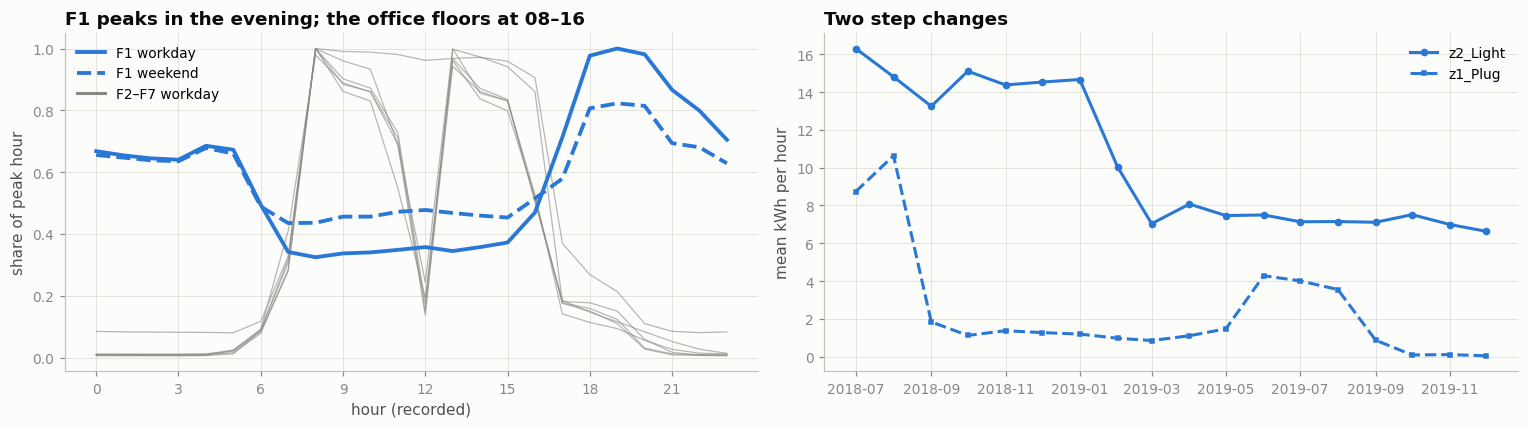

In [3]:
F = 1
display(kpi_row(F))
f1 = fh[(fh.floor == F) & fh.ok]
office = fh[fh.floor.isin([2, 3, 4, 5, 6, 7]) & fh.ok & (fh.day_type == "workday")]
off_prof = office.groupby(["floor", "hour"]).total_kwh.mean().unstack("floor")

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
for c in off_prof:
    a.plot(off_prof.index, off_prof[c] / off_prof[c].max(), color=viz.MUTED, lw=0.8, alpha=0.6)
for dt_, ls in (("workday", "-"), ("weekend", "--")):
    p = f1[f1.day_type == dt_].groupby("hour").total_kwh.mean()
    a.plot(p.index, p / f1[f1.day_type == "workday"].groupby("hour").total_kwh.mean().max(), color=viz.FLOOR_COLORS[F], ls=ls, lw=2.5, label=f"F1 {dt_}")
a.plot([], [], color=viz.MUTED, label="F2–F7 workday")
a.set_xticks(range(0, 24, 3)); a.set_xlabel("hour (recorded)"); a.set_ylabel("share of peak hour")
a.set_title("F1 peaks in the evening; the office floors at 08–16"); a.legend(loc="upper left")

zl, zp = point(F, "z2_Light(kW)").resample("MS").mean(), point(F, "z1_Plug(kW)").resample("MS").mean()
b.plot(zl.index, zl, color=viz.FLOOR_COLORS[F], marker="o", ms=4, label="z2_Light")
b.plot(zp.index, zp, color=viz.FLOOR_COLORS[F], ls="--", marker="s", ms=3, label="z1_Plug")
b.set_ylabel("mean kWh per hour"); b.set_title("Two step changes"); b.legend()
fig.tight_layout()

wk, we = f1[f1.is_workday & f1.hour.between(9, 16)].total_kwh.mean(), f1[~f1.is_workday & f1.hour.between(9, 16)].total_kwh.mean()
print(f"09–17 h load: workdays {wk:.0f} kWh/h, days off {we:.0f} kWh/h")
print(f"z2_Light: Jul 2018–Jan 2019 {zl[:'2019-01'].mean():.1f} → Mar–Dec 2019 {zl['2019-03':].mean():.1f} kWh/h "
      f"({zl['2019-03':].mean() / zl[:'2019-01'].mean() - 1:+.0%})")
night_plug = point(F, "z1_Plug(kW)")
night_plug = night_plug[night_plug.index.hour.isin(range(1, 5))].resample("D").mean()
print(f"z1_Plug night load: {night_plug['2018-08-20':'2018-09-03'].mean():.1f} kWh/h to 3 Sep 2018, "
      f"{night_plug['2018-09-04':'2018-09-30'].mean():.1f} after; Oct–Dec 2019 mean {zp['2019-10':].mean():.2f}")

**Checked against the cleaned data**

* **Holds:** the inverted profile, with weekday daytime below weekend daytime. Lighting is about 52% of energy. `z2_AC3`/`AC4`
  never run. `z2_Light` falls by about half from Feb 2019, a candidate retrofit or schedule change, which makes it a clean
  natural experiment for M&V. `z1_Plug` is near zero from Oct 2019. The `z2_Plug` outage from 22 Aug to 11 Sep 2018 is
  in the 00a outage register.
* **Holds, not applied:** the 7-hour clock-offset hypothesis. It is consistent with the lag test, but the floor still
  does not look like an office after a shift (00a §5).
* **Revised:** the year-on-year drop. Jul–Dec 2019 is 15% below Jul–Dec 2018 on raw cleaned data (the notebook said
  17%); weather-normalised it is about 12% (`03`).
* **Does not hold:** the "28–31 Aug 2018 event", described as sustained high load across meters. On cleaned data
  those days total 2.0–2.5 MWh, below F1's mean of 2.5 MWh/day. What does stand out that week is `z1_Plug` running about
  19 kW all night until it stops on 4 Sep 2018.

<a id="F2"></a>
## F2 · Fourteen AC units in one zone (owner: Shree)

*Salvaged from Shree's Floor 2 notebook (a raw-CSV EDA, removed with the old `eda` folder in commit 946a72d). Every figure and number below is re-derived from the cleaned data.*

**What's distinctive**

* **z2 has 14 AC meters:** one large unit (`z2_AC1`) and 13 small ones. `z2_AC11` is dead (exactly 0 for 18 months),
  and `AC12` and `AC14` are residual. Every other floor has at most four AC meters per zone.
* **Several small units run harder at night than by day.** `AC6`, `AC8` and `AC10` draw 2.4–3.2 times more from 01:00 to
  05:00 than in occupied hours. Together `AC2`–`AC10` used 18% of the floor's 2019 energy, which looks like a
  continuously cooled equipment or server space.
* **z3 is cooled by nothing but has a sensor.** In occupied hours it averages 26 °C while the cooled zones sit at
  18.5–22 °C. It is a natural control for the overcooling question.
* **No lunch shutdown** (00a §6), and 33 days off with a full AC run, the second most after F7.
* **The lux sensors see the lamps:** the hourly correlation of lux index with lighting kWh is 0.82–0.98 in the zones
  with lights.

,kWh/day,AC share,after-hours AC share,occupied cooled hours < 23 °C,days off with a ≥ 4 h AC run,power data received,sensor data received (outside blackout)
F2,681,78%,28%,80%,33,99.3%,92.6%


column,z2_AC2(kW),z2_AC3(kW),z2_AC4(kW),z2_AC5(kW),z2_AC6(kW),z2_AC7(kW),z2_AC8(kW),z2_AC9(kW),z2_AC10(kW)
occupied kWh/h,0.82,0.55,0.63,1.02,0.37,0.67,0.18,0.75,0.22
night kWh/h,0.66,0.50,0.55,0.56,0.90,0.37,0.59,0.41,0.67
night ÷ occupied,0.81,0.90,0.88,0.55,2.44,0.56,3.20,0.55,3.11


AC2–AC10 share of F2's 2019 energy: 18.5%


Occupied-hour mean temperature: {'z1': 21.5, 'z2': 22.1, 'z3': 26.2, 'z4': 18.6}
Monthly correlation between groups: {('A: AC2–4', 'B: AC5, 7, 9'): -0.32, ('A: AC2–4', 'C: AC6, 8, 10'): -0.07, ('B: AC5, 7, 9', 'A: AC2–4'): -0.32, ('B: AC5, 7, 9', 'C: AC6, 8, 10'): 0.39, ('C: AC6, 8, 10', 'A: AC2–4'): -0.07, ('C: AC6, 8, 10', 'B: AC5, 7, 9'): 0.39}
corr(lux index, lighting kWh): {'z1': 0.96, 'z2': 0.82, 'z3': 0.55, 'z4': 0.98}


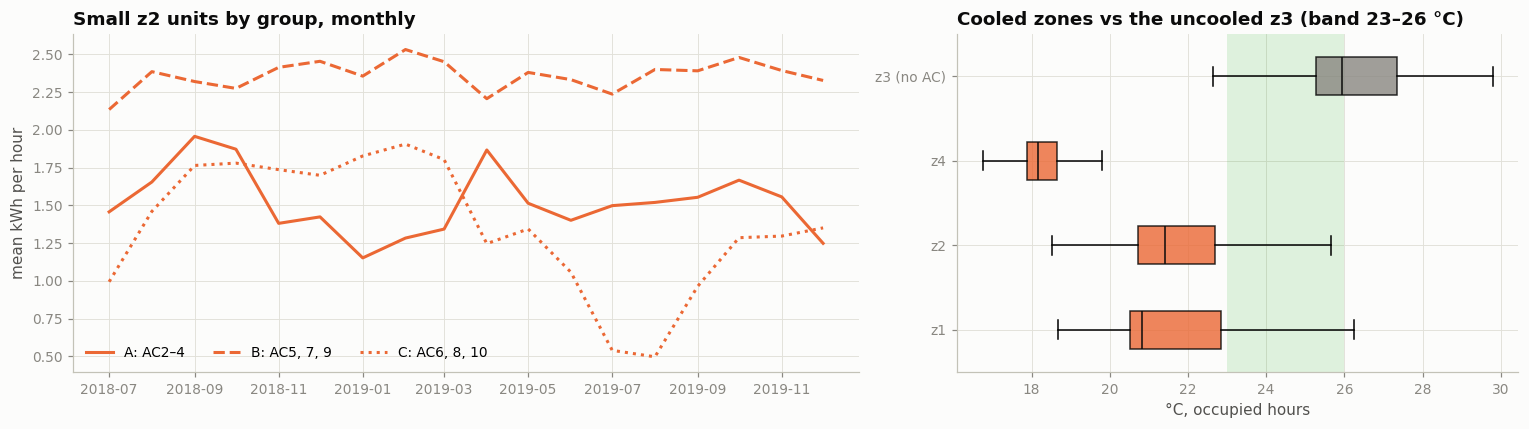

In [4]:
F = 2
display(kpi_row(F))
u = hp[(hp.floor == F) & (hp.channel == "ac")]
night = u[u.ts.dt.hour.between(1, 4)].groupby("column", observed=True).value.mean()
occ = u[u.ts.dt.hour.between(8, 16) & (u.ts.dt.dayofweek < 5)].groupby("column", observed=True).value.mean()
small = [f"z2_AC{i}(kW)" for i in range(2, 11)]
ratio = pd.DataFrame({"occupied kWh/h": occ, "night kWh/h": night, "night ÷ occupied": night / occ}).loc[small]
display(ratio.round(2).T)
y19 = hp[(hp.floor == F) & (hp.ts.dt.year == 2019) & hp.channel.isin(POWER)]
print(f"AC2–AC10 share of F2's 2019 energy: {y19[y19.column.isin(small)].value.sum() / y19.value.sum():.1%}")

groups = {"A: AC2–4": [2, 3, 4], "B: AC5, 7, 9": [5, 7, 9], "C: AC6, 8, 10": [6, 8, 10]}
mon = u.pivot_table(index=u.ts.dt.to_period("M").dt.to_timestamp(), columns="column", values="value", aggfunc="mean", observed=True)
gm = pd.DataFrame({g: mon[[f"z2_AC{i}(kW)" for i in ids]].sum(axis=1) for g, ids in groups.items()})

h2 = h[h.floor == F]
o2 = D.occupied(h2, require_temp=True)
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.4, 1]})
for (g, s), ls in zip(gm.items(), ("-", "--", ":")):
    a.plot(s.index, s, color=viz.FLOOR_COLORS[F], ls=ls, lw=2, label=g)
a.set_ylabel("mean kWh per hour"); a.set_title("Small z2 units by group, monthly"); a.legend(ncol=3, loc="lower left")
zones = ["z1", "z2", "z4", "z3"]
b.axvspan(LO, HI, color=viz.STATUS["good"], alpha=0.12, lw=0)
bp = b.boxplot([o2[o2.zone == z].temp_c for z in zones], vert=False, tick_labels=[f"{z} (no AC)" if z == "z3" else z for z in zones],
               patch_artist=True, showfliers=False, medianprops=dict(color=viz.INK))
for patch, z in zip(bp["boxes"], zones):
    patch.set_facecolor(viz.MUTED if z == "z3" else viz.FLOOR_COLORS[F]); patch.set_alpha(0.8)
b.set_xlabel("°C, occupied hours"); b.set_title("Cooled zones vs the uncooled z3 (band 23–26 °C)")
fig.tight_layout()
print("Occupied-hour mean temperature:", o2.groupby("zone").temp_c.mean().astype(float).round(1).to_dict())
print("Monthly correlation between groups:", gm.corr().round(2).where(lambda d: d < 1).stack().round(2).to_dict())
lux = h2.dropna(subset=["lux_idx", "light_kwh"]).groupby("zone").apply(lambda g: g.lux_idx.corr(g.light_kwh), include_groups=False)
print("corr(lux index, lighting kWh):", lux.round(2).to_dict())

**Checked against the cleaned data**

* **Holds:** 14 units in z2, with `z2_AC11` dead and `AC12`/`AC14` residual. Small units run overnight, and `AC2`–`AC10`
  are 18% of floor energy (the notebook said about 18%). z3 is an uncooled control at about 26 °C. The large units are off
  at night. The 23 Jan – 12 Feb 2019 dip is a metering gap, not a shutdown (00a §2). Lux tracks the lamps.
* **Not established:** duty rotation in three groups that swap over. Group C (`AC6/8/10`) steps down in Apr and
  Jul–Aug 2019 and group A rises in Apr 2019, but group B barely moves, A does not take up C's Jul–Aug drop, and the
  monthly correlations between groups are weak (−0.32 to +0.39). On hourly cleaned data the small units look like a
  continuously cooled space with changing duty, not a clean three-way rotation.
* **Revised:** the overcooling percentages (93–97% of occupied *minutes* below 23 °C, Apr–Dec 2019) become 77–100% of
  occupied, AC-on *hours* over all sensor-valid months. z4 is still the extreme case, at 18.5 °C.
* **Dropped:** "the floor got colder in 2019 while using more cooling". The comparison crosses the 6 Mar 2019 sensor
  reinstall (00a summary), so it cannot separate a setpoint change from a sensor change.

<a id="F3"></a>
## F3 · Weekend AC programmes and a creeping baseload (owner: Mik)

*Salvaged from Mik's Floor 3 notebook (a raw-CSV EDA, removed with the old `eda` folder in commit 946a72d). Every figure and number below is re-derived from the cleaned data.*

**What's distinctive**

* **The longest whole-floor outage:** every meter is offline from 11 Oct to 21 Nov 2018 (about 6 weeks), and the large AC
  meters drop out again on 26 Mar – 2 Apr 2019. The large AC meters also go dark together in Jan–Feb 2019 while the
  small units keep reporting, so they sit on their own communication path.
* **The full weekday AC programme runs on a few days off:** 27 Apr 2019, 8 Sep 2018, and 14, 15 and 21 Sep 2019. These
  are the labelled events the anomaly detector in `04` is validated against.
* **On days off, lighting and plug use more than the AC.** Over the record, non-working days used 3.8 MWh of lighting
  and 2.5 MWh of plug against 1.9 MWh of AC.
* **The night plug baseload creeps up** from about 0.49 to 0.66 kWh/h (0.68 by late 2019), with a step in Apr 2019. In the same month
  `z1_AC4`'s 0.07 kW standby draw disappears, which points to a metering or control change.

,kWh/day,AC share,after-hours AC share,occupied cooled hours < 23 °C,days off with a ≥ 4 h AC run,power data received,sensor data received (outside blackout)
F3,521,65%,5%,80%,11,90.8%,91.9%


,day,day_type,first_hour,last_hour,hours,ac_kwh
376,Sat 27 Apr 2019,weekend,7,16,9,334.0
356,Sat 08 Sep 2018,weekend,10,18,9,267.0
400,Sat 14 Sep 2019,weekend,7,16,10,234.0
401,Sun 15 Sep 2019,weekend,9,16,8,216.0
404,Sat 21 Sep 2019,weekend,8,16,8,155.0


Days-off energy, MWh: {'ac_kwh': 1.9, 'light_kwh': 3.8, 'plug_kwh': 2.5}
Night plug baseload: Jul 2018–Mar 2019 0.49 → Apr–Dec 2019 0.66 kWh/h (Nov 2018 left out: meters offline)


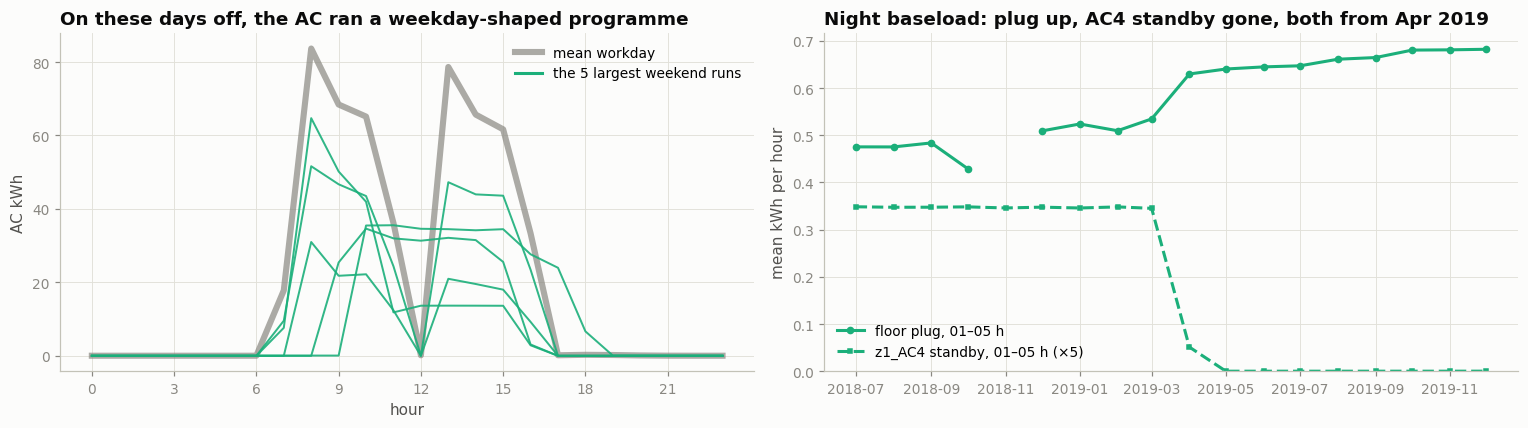

In [5]:
F = 3
display(kpi_row(F))
f3 = fh[fh.floor == F]
top = ac_runs[ac_runs.floor == F].nlargest(5, "excess_kwh")
display(top[["day", "day_type", "first_hour", "last_hour", "hours", "ac_kwh"]].assign(day=top.day.dt.strftime("%a %d %b %Y")).round(0))
work = f3[f3.ok & (f3.day_type == "workday")].groupby("hour").ac_kwh.mean()

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
a.plot(work.index, work, color=viz.MUTED, lw=4, alpha=0.7, label="mean workday")
for d in top.day:
    p = f3[f3.ts.dt.normalize() == d].set_index("hour").ac_kwh
    a.plot(p.index, p, color=viz.FLOOR_COLORS[F], lw=1.3, alpha=0.9)
a.plot([], [], color=viz.FLOOR_COLORS[F], label="the 5 largest weekend runs")
a.set_xticks(range(0, 24, 3)); a.set_xlabel("hour"); a.set_ylabel("AC kWh"); a.legend()
a.set_title("On these days off, the AC ran a weekday-shaped programme")

pl = h[h.floor == F].groupby("ts").plug_kwh.sum(min_count=1)
pl = pl[pl.index.hour.isin(range(1, 5))].resample("MS").mean()
pl[pd.Timestamp("2018-11-01")] = np.nan          # meters offline most of the month (00a §2)
a4 = point(F, "z1_AC4(kW)")
a4 = a4[a4.index.hour.isin(range(1, 5))].resample("MS").mean()
b.plot(pl.index, pl, color=viz.FLOOR_COLORS[F], marker="o", ms=4, label="floor plug, 01–05 h")
b.plot(a4.index, a4 * 5, color=viz.FLOOR_COLORS[F], ls="--", marker="s", ms=3, label="z1_AC4 standby, 01–05 h (×5)")
b.set_ylabel("mean kWh per hour"); b.set_ylim(0, None); b.legend(loc="lower left")
b.set_title("Night baseload: plug up, AC4 standby gone, both from Apr 2019")
fig.tight_layout()

nw = f3[~f3.is_workday][["ac_kwh", "light_kwh", "plug_kwh"]].sum() / 1000
print("Days-off energy, MWh:", nw.astype(float).round(1).to_dict())
print(f"Night plug baseload: Jul 2018–Mar 2019 {pl[:'2019-03'].mean():.2f} → "
      f"Apr–Dec 2019 {pl['2019-04':].mean():.2f} kWh/h (Nov 2018 left out: meters offline)")

**Checked against the cleaned data**

* **Holds:** the four largest weekend runs are the same days the notebook found (27 Apr 2019, 8 Sep 2018, 14 and 15 Sep
  2019), and the pipeline adds 21 Sep 2019. So do the multi-week meter outage, the separate comms path of the large AC
  meters, lighting dominating days-off energy, the plug-baseload creep (0.49 → 0.66 kWh/h; the notebook had 0.46 → 0.67), the disappearing
  `z1_AC4` standby, and systemic overcooling (z4 19.5 °C, z5 20.2 °C).
* **Not reproduced:** the partial morning AC run on Royal Ploughing Day (9 May 2019). It does not pass the ≥ 4-hour,
  above-night-threshold rule used here, so it is too short to count as a full programme.

<a id="F4"></a>
## F4 · All-hours averages hide the overcooling (owner: Kenneth)

*Salvaged from Kenneth's Floor 4 notebook (a raw-CSV EDA, removed with the old `eda` folder in commit 946a72d). Every figure and number below is re-derived from the cleaned data.*

**What's distinctive**

* **The comfort trap.** Averaged over *all* hours, F4's zones read 24.5–25.7 °C, which looks comfortable. In occupied,
  cooled hours they average 20.1–21.7 °C, and 79–92% of those hours are below 23 °C.
* **A reconnect burst on 2018-11-21 at 15:20,** when the floor came back from its outage (29 Oct – 21 Nov 2018):
  `z1_Plug` 87 kW, `z5_Light` 59 kW and `z1_AC1–3` 10–22 kW, all for one minute. Kenneth's caps are kept in
  `registry.GLITCH_CAPS`.
* **The `z1_AC1–3` meters are offline from late Feb to late May 2019,** a gap the README does not name. They carry
  0.2% of z1's cooling, so it does not matter for energy, but it lowers F4's power completeness outside the named
  outages to 95%.
* **z2 is the humid zone:** 38% of its occupied, cooled hours are above 70% RH. Other zones are at 0–2%.

,kWh/day,AC share,after-hours AC share,occupied cooled hours < 23 °C,days off with a ≥ 4 h AC run,power data received,sensor data received (outside blackout)
F4,507,68%,5%,82%,21,91.4%,92.9%


,column,rule,minutes,first,detail
108,z1_AC1(kW),glitch_cap,1,2018-11-21 15:20:00,> 5 kW (floor notebook)
110,z1_AC2(kW),glitch_cap,1,2018-11-21 15:20:00,> 8 kW (floor notebook)
112,z1_AC3(kW),glitch_cap,1,2018-11-21 15:20:00,> 8 kW (floor notebook)
118,z1_Plug(kW),range,1,2018-11-21 15:20:00,"outside [0, 80] kW"
147,z5_Light(kW),glitch_cap,1,2018-11-21 15:20:00,> 15 kW (floor notebook)


Occupied cooled hours above 70% RH: {'z1': 0.0, 'z2': 0.38, 'z4': 0.02, 'z5': 0.02}
z1_AC1–3 offline days in 2019: 90 (24 Feb – 26 May)


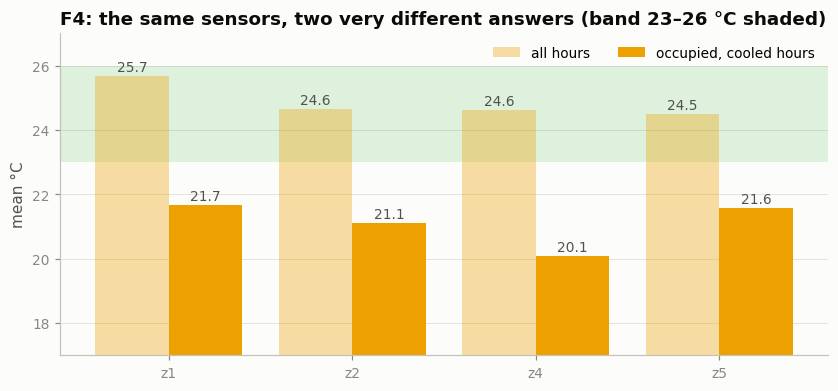

In [6]:
F = 4
display(kpi_row(F))
log = pd.read_csv(C.DATA_CLEANED / "cleaning_log.csv")
burst = log[(log.floor == F) & (log.rule != "interpolated") & log["first"].str.startswith("2018-11-21 15:20")]
display(burst[["column", "rule", "minutes", "first", "detail"]])

h4 = h[(h.floor == F) & h.zone.isin(R.comfort_zones(F))]
cool = D.occupied(h4, require_temp=True, ac_on=True)
t = pd.DataFrame({"all hours": h4[h4.temp_ok].groupby("zone").temp_c.mean(),
                  "occupied, cooled hours": cool.groupby("zone").temp_c.mean()})
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(t))
ax.axhspan(LO, HI, color=viz.STATUS["good"], alpha=0.12, lw=0)
ax.bar(x - 0.2, t["all hours"], 0.4, color=viz.FLOOR_COLORS[F], alpha=0.35, label="all hours")
ax.bar(x + 0.2, t["occupied, cooled hours"], 0.4, color=viz.FLOOR_COLORS[F], label="occupied, cooled hours")
for i, (v1, v2) in enumerate(t.to_numpy()):
    ax.text(i - 0.2, v1 + 0.15, f"{v1:.1f}", ha="center", fontsize=9, color=viz.INK_2)
    ax.text(i + 0.2, v2 + 0.15, f"{v2:.1f}", ha="center", fontsize=9, color=viz.INK_2)
ax.set_xticks(x, t.index); ax.set_ylim(17, 27); ax.set_ylabel("mean °C"); ax.legend(loc="upper right", ncol=2)
ax.set_title("F4: the same sensors, two very different answers (band 23–26 °C shaded)")
ax.grid(axis="x", visible=False)
print("Occupied cooled hours above 70% RH:", (cool.rh_pct > 70).groupby(cool.zone).mean().round(2).to_dict())
off = health[(health.floor == F) & health.column.isin(["z1_AC1(kW)", "z1_AC2(kW)", "z1_AC3(kW)"]) & (health.received == 0)]
print(f"z1_AC1–3 offline days in 2019: {off[off.day.dt.year == 2019].day.nunique()} "
      f"({off[off.day.dt.year == 2019].day.min():%d %b} – {off[off.day.dt.year == 2019].day.max():%d %b})")

**Checked against the cleaned data**

* **Holds:** the 2018 single-minute spikes, cleaned by the glitch caps and the spike rule (table above). `z1_AC4`
  carries 99.8% of z1's AC. The sensor blackout ends on 5–6 Mar 2019. The all-hours zone means of 24.5–25.7 °C match.
* **Does not hold:** "post-March 2019 temperatures align with tropical office comfort standards". The all-hours mean
  includes nights and weekends with the AC off. In occupied, cooled hours F4 is the third most overcooled floor (82%).
* **Partly holds:** "RH frequently exceeds 70%". It does in z2 (38% of occupied, cooled hours) but not in the other zones.

<a id="F5"></a>
## F5 · The metering traps (owner: Terence)

*Salvaged from Terence's Floor 5 notebook (a raw-CSV EDA, removed with the old `eda` folder in commit 946a72d). Every figure and number below is re-derived from the cleaned data.*

**What's distinctive**

F5 is the floor the dashboard was built on, so its traps were found first and written into `registry.py` for every
floor.

* **z1's real cooling is on `AC4`** (99.7%). `AC1`–`AC3` are standby or residual. The same is true on F3, F4 and F7.
* **z3 is a stairwell** with no AC and no sensor. A zero there means "not metered", not "efficient".
* **z1's sensor sits in a supply-air path.** With the AC running it averages 17.3 °C against 21.6–22.8 °C for the other
  zones, and after the 6 Mar 2019 reinstall it reads as low as 11 °C. It is a diagnostic, never a comfort reading.
* **A z2↔z4 meter transfer on 2019-09-27.** The z2:z4 split flips from 0.88 to 1.17 while the pair's total stays flat
  (00a §7). Zone-level comparisons must not cross this date.
* **The least overcooled office floor (68%),** but z1 and z2 lose their sensors for 45 and 69 days in Jul–Sep 2019.

,kWh/day,AC share,after-hours AC share,occupied cooled hours < 23 °C,days off with a ≥ 4 h AC run,power data received,sensor data received (outside blackout)
F5,520,66%,1%,68%,10,97.5%,87.2%


Mean °C, occupied with AC on: {'z1': 17.3, 'z2': 22.1, 'z4': 21.6, 'z5': 22.8}
z1 hourly minimum: 15.5 °C before 2019-03-06, 11.0 °C after
Share of z1 AC by unit: {'z1_AC4(kW)': '99.66%', 'z1_AC2(kW)': '0.20%', 'z1_AC3(kW)': '0.14%', 'z1_AC1(kW)': '0.01%'}


,zone,from,to,what,note
0,z2,2019-07-20 07:36,2019-09-27 14:15,sensors,69.3 days — no indoor temperature for Aug and ...
1,z1,2019-08-13 13:39,2019-09-27 14:26,sensors,45.0 days
2,*,2019-01-23 09:41,2019-02-12 15:13,ac,20.2 days — all four AC channels to the minute...
3,z4,2019-04-10 02:55,2019-04-26 14:47,sensors,16.5 days
4,z2,2019-05-12 01:19,2019-05-27 12:29,sensors,15.5 days
5,z2,2019-05-14 06:54,2019-05-27 12:33,light+plug,13.2 days
6,z4,2019-12-13 17:12,2019-12-19 11:35,sensors,5.8 days


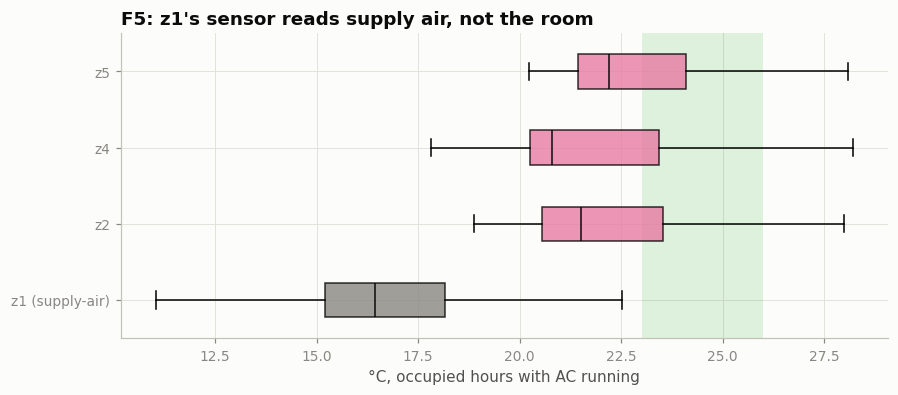

In [7]:
F = 5
display(kpi_row(F))
h5 = h[h.floor == F]
o5 = D.occupied(h5, require_temp=True, ac_on=True)
zones = ["z1", "z2", "z4", "z5"]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(LO, HI, color=viz.STATUS["good"], alpha=0.12, lw=0)
bp = ax.boxplot([o5[o5.zone == z].temp_c for z in zones], vert=False, patch_artist=True, showfliers=False,
                tick_labels=["z1 (supply-air)" if z == "z1" else z for z in zones], medianprops=dict(color=viz.INK))
for patch, z in zip(bp["boxes"], zones):
    patch.set_facecolor(viz.MUTED if z == "z1" else viz.FLOOR_COLORS[F]); patch.set_alpha(0.8)
ax.set_xlabel("°C, occupied hours with AC running"); ax.set_title("F5: z1's sensor reads supply air, not the room")
z1 = h5[(h5.zone == "z1") & h5.temp_ok]
print("Mean °C, occupied with AC on:", o5.groupby("zone").temp_c.mean().astype(float).round(1).to_dict())
print(f"z1 hourly minimum: {z1[z1.ts < '2019-03-06'].temp_c.min():.1f} °C before 2019-03-06, "
      f"{z1[z1.ts > '2019-03-06'].temp_c.min():.1f} °C after")
units = AN.unit_status(hp[hp.floor == F])
print("Share of z1 AC by unit:", (units[units.zone == "z1"].set_index("column").kwh.astype(float) / units[units.zone == "z1"].kwh.sum()).map("{:.2%}".format).to_dict())
pd.DataFrame(R.KNOWN_OUTAGES, columns=["zone", "from", "to", "what", "note"])

**Checked against the cleaned data**

* **Holds:** z1 is carried by `AC4`. z3 has no AC and no sensor. The sensor blackout runs from 15 Sep 2018 to
  5 Mar 2019 (z1/z2 stop on 12 Sep, 00a §2). The z1 sensor drops out in Aug–Sep 2019. The 2018 light and plug spikes
  are capped (`registry.GLITCH_CAPS`). The lux channel peaks around 80, so it is a relative signal only. AC is 66% of
  energy.
* **Revised:** "z1_AC1 is dead". It is *residual* (4 kWh over 18 months), not exactly zero. The cold z1 readings are
  explained by a supply-air sensor rather than a defect.
* **Revised:** "occupied ~07:00–19:00". The measured AC schedule is 08:00–16:59 with a lunch shutdown (00a §6). The
  later finish in the notebook was lighting and plug load.

<a id="F6"></a>
## F6 · A truncated file, and a different layout (owner: Williams)

*Salvaged from Williams's Floor 6 notebook (a raw-CSV EDA, removed with the old `eda` folder in commit 946a72d). Every figure and number below is re-derived from the cleaned data.*

**What's distinctive**

* **The source file ends at 2019-10-22 13:27,** and its last row is corrupt (`Date = "2"`). F6 has about 9.7 months
  of 2019, so annual F6 figures and Nov–Dec comparisons are not available. z2's sensor is already dark from 2 Oct 2019.
* **The four-unit AC zone is z4, not z1.** `z4_AC4` carries 99.4% of z4's cooling, and z1 has a single unit. Code that
  assumes "z1 has four ACs" is wrong on F6.
* **Year on year is flat.** Jul–Oct kWh/day is +8%, −4%, +3% and +1% against 2018. F6 is not affected by the Jan–Feb
  2019 AC-meter gap.
* **The strongest candidate meter transfer in the building** is z1 against z5 in mid-June 2019 (00a §7). It is not yet
  confirmed.

,kWh/day,AC share,after-hours AC share,occupied cooled hours < 23 °C,days off with a ≥ 4 h AC run,power data received,sensor data received (outside blackout)
F6,520,59%,6%,75%,19,87.0%,77.3%


Last hour with metered data: 2019-10-22 13:00:00
Share of z4 AC by unit: {'z4_AC4(kW)': '99.36%', 'z4_AC2(kW)': '0.48%', 'z4_AC3(kW)': '0.08%', 'z4_AC1(kW)': '0.08%'}
The notebook's low days, as the shared calendar labels them:
              kWh day type
2019-07-17  46.0  holiday
2019-04-12  71.0  closure
2018-12-05  53.0  holiday
2018-10-23  54.0  holiday
2019-01-01  47.0  holiday
Highest hour: 2018-07-02 08:00, 125 kWh (101 kWh AC)


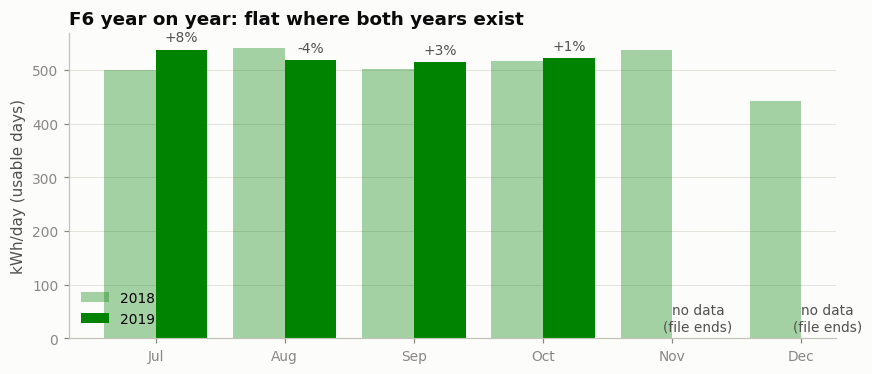

In [8]:
F = 6
display(kpi_row(F))
f6 = fh[fh.floor == F]
print("Last hour with metered data:", f6.dropna(subset=["ac_kwh"]).ts.max())
u6 = AN.unit_status(hp[hp.floor == F])
z4 = u6[u6.zone == "z4"].set_index("column").kwh
print("Share of z4 AC by unit:", (z4.astype(float) / z4.sum()).map("{:.2%}".format).to_dict())

d6 = fd[(fd.floor == F) & fd.ok]
m = d6.groupby([d6.day.dt.year.rename("year"), d6.day.dt.month.rename("month")]).total_kwh.mean().unstack("year")
m = m.loc[7:12]
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(m))
ax.bar(x - 0.2, m[2018], 0.4, color=viz.FLOOR_COLORS[F], alpha=0.35, label="2018")
ax.bar(x + 0.2, m[2019], 0.4, color=viz.FLOOR_COLORS[F], label="2019")
for i, (a_, b_) in enumerate(zip(m[2018], m[2019])):
    lab = f"{b_ / a_ - 1:+.0%}" if np.isfinite(b_) else "no data\n(file ends)"
    ax.text(i + 0.2, (b_ if np.isfinite(b_) else 0) + 15, lab, ha="center", fontsize=9, color=viz.INK_2)
ax.set_xticks(x, pd.to_datetime([f"2019-{mm}-01" for mm in m.index]).strftime("%b")); ax.legend(loc="lower left")
ax.set_ylabel("kWh/day (usable days)"); ax.set_title("F6 year on year: flat where both years exist")
ax.grid(axis="x", visible=False)

flagged = pd.to_datetime(["2019-07-17", "2019-04-12", "2018-12-05", "2018-10-23", "2019-01-01"])   # Williams's low days
dt6 = D.load_day_types().query("floor == @F").assign(date=lambda d: pd.to_datetime(d.date)).set_index("date")
day_kwh = fd[fd.floor == F].set_index("day").total_kwh
print("The notebook's low days, as the shared calendar labels them:\n",
      pd.DataFrame({"kWh": day_kwh.reindex(flagged).round(0), "day type": dt6.day_type.reindex(flagged)}).to_string())
top_h = f6.loc[f6.total_kwh.idxmax()]
print(f"Highest hour: {top_h.ts:%Y-%m-%d %H:00}, {top_h.total_kwh:.0f} kWh ({top_h.ac_kwh:.0f} kWh AC)")

**Checked against the cleaned data**

* **Holds:** the truncation and corrupt last row (handled in `io.load_raw`). z4's AC1–AC3 are almost always off. The
  month-by-month year on year (+8%, −4%, +3%, +1% against the notebook's +7.9%, −3.0%, +3.1% and +0.5%). The ten-fold
  weekday/weekend drop.
* **Explained:** the "one-off low days" (2019-07-17, 2019-04-12, 2018-12-05, 2018-10-23, 2019-01-01) are all holidays or a
  detected closure in the shared calendar, so they are not anomalies.
* **Cannot be checked at this grain:** the 166 kW one-minute peak at 2019-02-12 15:14. Hourly, that afternoon is
  unremarkable, and F6's highest hour is a morning start-up (2018-07-02 08:00, 125 kWh). The minute lands one minute
  after the other floors' AC loggers reconnected, so treat it as suspect.
* **Dropped:** "the floor ran cooler in 2019". The comparison crosses the 6 Mar 2019 sensor reinstall (00a summary).

<a id="F7"></a>
## F7 · Dead z1_AC1, the most weekend AC, the most overcooling (owner: Sana)

*Salvaged from Sana's Floor 7 notebook (a raw-CSV EDA, removed with the old `eda` folder in commit 946a72d). Every figure and number below is re-derived from the cleaned data.*

**What's distinctive**

* **`z1_AC1` is dead** (exactly 0 for 18 months). z1's cooling is on `AC4` (98.5%), and `AC2`/`AC3` carry about 0.7% each.
* **The most AC on days off:** 50 weekends, holidays or closures with a ≥ 4-hour AC run, the most in the building.
* **The most overcooled floor:** 83% of occupied, cooled hours are below 23 °C, and z1 averages 20.2 °C. Averaged over all
  hours the same zones read 24.8–26.5 °C, the same trap as F4.
* **`z3_Plug` almost switches off in Feb–Apr 2019,** from about 0.22 to 0.03 kWh/h, and then returns to its old level.

,kWh/day,AC share,after-hours AC share,occupied cooled hours < 23 °C,days off with a ≥ 4 h AC run,power data received,sensor data received (outside blackout)
F7,710,78%,12%,83%,50,98.7%,96.4%


Hourly max of z1_AC2: 0.63 kWh; of z1_AC4: 38.5


z3_Plug: Jul 2018–Jan 2019 0.21, Feb–Apr 2019 0.04, May–Dec 2019 0.21 kWh/h
Mean °C, all hours: {'z1': 24.8, 'z2': 25.9, 'z4': 26.0, 'z5': 26.5}
Mean °C, occupied cooled hours: {'z1': 20.2, 'z2': 22.2, 'z4': 21.2, 'z5': 22.4}


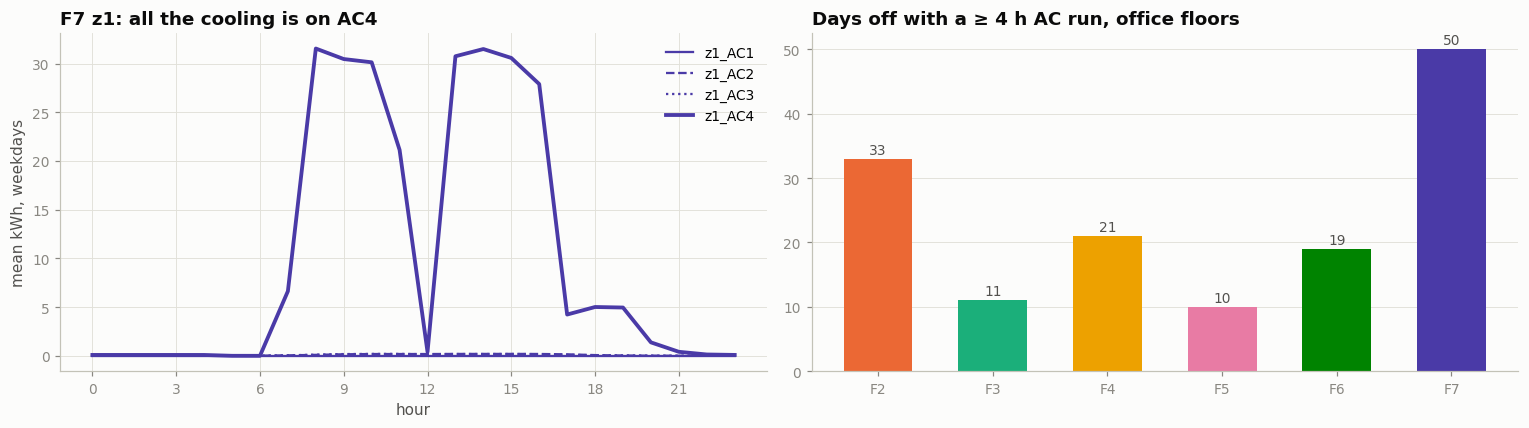

In [9]:
F = 7
display(kpi_row(F))
u7 = hp[(hp.floor == F) & (hp.zone == "z1") & (hp.channel == "ac")]
u7 = u7[u7.ts.dt.dayofweek < 5]
prof = u7.groupby([u7.ts.dt.hour.rename("hour"), "column"], observed=True).value.mean().unstack("column")

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 4))
for c, ls in zip(sorted(prof.columns), ("-", "--", ":", "-")):
    a.plot(prof.index, prof[c], color=viz.FLOOR_COLORS[F], ls=ls, lw=2.5 if "AC4" in c else 1.5, label=c.split("(")[0])
a.set_xticks(range(0, 24, 3)); a.set_xlabel("hour"); a.set_ylabel("mean kWh, weekdays"); a.legend()
a.set_title("F7 z1: all the cooling is on AC4")

n = ac_runs[ac_runs.floor != 1].groupby("floor").size()
b.bar([f"F{f}" for f in n.index], n, color=[viz.FLOOR_COLORS[f] for f in n.index], width=0.6)
for i, v in enumerate(n):
    b.text(i, v + 0.8, str(v), ha="center", fontsize=9, color=viz.INK_2)
b.set_title("Days off with a ≥ 4 h AC run, office floors"); b.grid(axis="x", visible=False)
fig.tight_layout()

print("Hourly max of z1_AC2:", round(float(point(F, "z1_AC2(kW)").max()), 2), "kWh; of z1_AC4:", round(float(point(F, "z1_AC4(kW)").max()), 1))
z3 = point(F, "z3_Plug(kW)").resample("MS").mean()
print(f"z3_Plug: Jul 2018–Jan 2019 {z3[:'2019-01'].mean():.2f}, Feb–Apr 2019 {z3['2019-02':'2019-04'].mean():.2f}, "
      f"May–Dec 2019 {z3['2019-05':].mean():.2f} kWh/h")
h7 = h[(h.floor == F) & h.zone.isin(R.comfort_zones(F))]
print("Mean °C, all hours:", h7[h7.temp_ok].groupby("zone").temp_c.mean().astype(float).round(1).to_dict())
print("Mean °C, occupied cooled hours:", D.occupied(h7, require_temp=True, ac_on=True).groupby("zone").temp_c.mean().astype(float).round(1).to_dict())

**Checked against the cleaned data**

* **Holds:** power data is far more complete than sensor data. The missing months are Sep 2018 – Mar 2019 (the
  blackout). AC is the dominant load, with its 08:00 and 13:00 start-ups. z3 has only lighting and plug, and `z3_Plug`
  drops in early 2019. The all-hours zone means (24.75, 25.87, 26.04, 26.46 °C) match exactly.
* **Does not hold:** "zone 1 AC usage is concentrated in AC2 and AC4". On cleaned data `z1_AC2` never exceeds 0.63 kWh in
  an hour and carries 0.7% of z1's AC, so `AC4` alone carries the zone. `z1_AC1` is dead, not merely idle.
* **Reframed:** "temperature and humidity are relatively similar across zones". That is true of all-hours means, but in
  occupied, cooled hours z1 is about 2 °C colder than z2 and z5.
* **Dropped:** the year-over-year changes in each column's maximum and minimum (for example `z3_Plug` max +211%). A
  single extreme minute is not a robust statistic, and the cleaned data caps such minutes.

---
**Where these findings go next.** The dead, residual and always-on meters feed the unit register in 00a §4 and the
recommendations in `06`. The weekend AC runs (F2, F3, F7) are the labelled events `04` is validated against. The
overcooling contrasts (F2 z3, F4 and F7 all-hours vs occupied) back the setpoint recommendation. The step changes
(F1 `z2_Light`, F3 plug baseload, F5 z2↔z4) are reasons not to train zone-level baselines across those dates.